<a href="https://colab.research.google.com/github/HuriyaAhmerr/AIP/blob/main/AIP_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Universal Plus – E-Mail Marketing Targeting
**IB9BW0 Analytics in Practice**

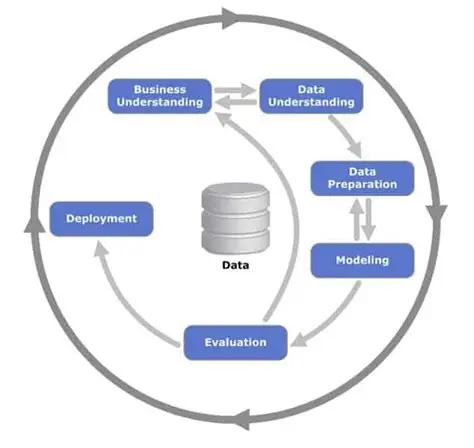





## 1. Business Understanding

**Business figures from the board:**
- Cost per e-mail: £3.50
- Value of a visit: £93 average spend × 30% margin ≈ £28


**Business problem:**

Today, decisions about who receives a campaign e-mail are mostly made by rules of thumb or at random. Targeting uninterested customers costs money, and several past campaigns were not successful.

The company wants a system that predicts whether each customer will visit the shop after a campaign.

-------------------------------------------------

**Analytics problem:**

for each customer, predict whether they will visit the shop in the two weeks after the campaign (`visit` = 1 or 0), using only information available *before* the campaign plus the e-mail they receive.

As the answer is a category, this is a *classification* problem. So estimate each customer's chance of visiting under each choice (Men's e-mail, Women's e-mail, no e-mail), then convert these into expected profit (chance of visit × £28 − £3.50 per e-mail), and finally recommend the most profitable choice.




## 2. Data Understanding


### The Datasets
| File | Rows | Columns | Contains `visit`? |
|---|---|---|---|
| `campaign_data.csv` | 52,000 | 21 | Yes |
| `next_campaign.csv` | 12,000 | 20 | No |

**campaign_data.csv** – contains the 52,000 customers who took part in the test campaign. For each
customer it records 21 attributes, including the e-mail they received and whether they visited the shop.  

**next_campaign.csv** – contains 12,000 further customers from the same campaign. It holds the same
information as the first file, except that it does not say whether these customers visited the shop. Universal
Plus has shared this file to see how your system would be used in its next campaign


In [4]:
print(open("readme.txt").read())   # delete this at the end

1. Title: E-Mail Marketing

Universal Plus randomly sent an e-mail marketing campaign to some of its customers.
Some customers received a campaign on women's products, some received a campaign on men's products,
and some did not receive an e-mail campaign at all.
The company collected data for all of these customers (including the ones who did not receive the campaign)
during the two weeks following the e-mail campaign.

2. Files and number of instances

   campaign_data.csv            52,000 customers, all 21 attributes listed below.
   next_campaign.csv		12,000 further customers from the same campaign. All attributes 				are provided except `visit`, which has been withheld. Universal 				Plus has shared this file to see how your system would be used 					in its next campaign.

3. Number of attributes: 21

4. Attribute information:

  1) Customer_ID: Customer identification number
  2) recency: Months since last purchase before the marketing campaign
  3) purchase_segment: Categorisat

-----
### 2.1 Load the data and take a first look

In [5]:
# Import the libraries
import pandas as pd
import numpy as np

# Load the files.
df = pd.read_csv("campaign_data.csv")
nxt = pd.read_csv("next_campaign.csv")

# How many rows and columns?
print(df.shape)
print(nxt.shape)

(48804, 21)
(12000, 20)


In [6]:
# The first five rows
df.head()

,Customer_ID,recency,purchase_segment,purchase,mens,womens,zip_area,new_customer,channel,email_segment,...,dependent,account,employed,phone,delivery,marriage,payment_card,satisfaction_score,spend,visit
0,30000001,12.0,1) 0 - 100,81.61,1,0,Urban,0,Phone,No E-Mail,...,1.0,1.0,1.0,1.0,1.0,0.0,1.0,NaN,0.0,0.0
1,30000004,NaN,3) 200 - 350,258.74,1,0,Urban,0,Multichannel,Mens E-Mail,...,1.0,1.0,1.0,1.0,3.0,0.0,1.0,8.0,0.0,0.0
2,30000005,6.0,3) 200 - 350,239.96,1,0,Suburban,0,Phone,No E-Mail,...,0.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,0.0,0.0
3,30000006,7.0,3) 200 - 350,268.18,1,1,Rural,1,Web,Womens E-Mail,...,1.0,1.0,1.0,1.0,3.0,2.0,0.0,5.0,0.0,0.0
4,30000007,1.0,3) 200 - 350,311.52,0,1,Suburban,0,Web,No E-Mail,...,0.0,1.0,1.0,1.0,3.0,1.0,1.0,8.0,0.0,0.0


In [7]:
# The structure: column names, data types and the number of non-missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48804 entries, 0 to 48803
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Customer_ID         48804 non-null  int64  
 1   recency             45270 non-null  float64
 2   purchase_segment    48781 non-null  object 
 3   purchase            48804 non-null  float64
 4   mens                48804 non-null  int64  
 5   womens              48804 non-null  int64  
 6   zip_area            48078 non-null  object 
 7   new_customer        48804 non-null  int64  
 8   channel             48085 non-null  object 
 9   email_segment       48803 non-null  object 
 10  age                 46902 non-null  float64
 11  dependent           48803 non-null  float64
 12  account             48803 non-null  float64
 13  employed            48803 non-null  float64
 14  phone               48803 non-null  float64
 15  delivery            48803 non-null  float64
 16  marr

In [8]:
# Summary statistics of the numerical columns: check min and max for odd values
df.describe().round(2)

,Customer_ID,recency,purchase,mens,womens,new_customer,age,dependent,account,employed,phone,delivery,marriage,payment_card,satisfaction_score,spend,visit
count,48804.00,45270.00,48804.00,48804.00,48804.00,48804.0,46902.00,48803.00,48803.0,48803.00,48803.00,48803.00,48803.00,48803.00,19667.00,48772.00,48803.00
mean,30030054.30,6.04,241.75,0.55,0.55,0.5,35.37,0.38,1.0,1.00,0.94,1.71,1.04,0.74,7.00,15.29,0.16
std,17351.34,3.45,257.84,0.50,0.50,0.5,8.94,0.49,0.0,0.04,0.24,0.93,0.87,0.44,1.45,43.07,0.37
min,30000001.00,1.00,25.00,0.00,0.00,0.0,20.00,0.00,1.0,0.00,0.00,1.00,0.00,0.00,2.00,0.00,0.00
25%,30015029.75,3.00,63.97,0.00,0.00,0.0,28.00,0.00,1.0,1.00,1.00,1.00,0.00,0.00,6.00,0.00,0.00
50%,30030050.50,6.00,156.52,1.00,1.00,1.0,34.00,0.00,1.0,1.00,1.00,1.00,1.00,1.00,7.00,0.00,0.00
75%,30045112.50,9.00,324.32,1.00,1.00,1.0,41.00,1.00,1.0,1.00,1.00,3.00,2.00,1.00,8.00,0.00,0.00
max,30060082.00,12.00,3387.49,1.00,1.00,1.0,62.00,1.00,1.0,1.00,1.00,3.00,2.00,1.00,10.00,499.00,1.00


**Findings**
- `Customer_ID` is just an identifier. It is stored as a number, but it is not a quantity.
- `purchase_segment`, `zip_area`, `channel` and `email_segment` are stored as text.
- `delivery` and `marriage` are stored as numbers, but they are categories (e.g. delivery: 1 = home, 2 = work, 3 = multiple).
- Some columns have fewer than 52,000 non-missing values which means there are missing values.
- `spend` is recorded *after* the campaign, so it will not be known when deciding who to e-mail.

-----
## 2.2 Investigating what does "missing" mean here?


In [9]:
# Count every value in the text columns, including missing values
for column in ["zip_area", "channel", "purchase_segment"]:
    print(df[column].value_counts(dropna=False), "\n")

zip_area
Suburban    21657
Urban       19203
Rural        7218
NaN           726
Name: count, dtype: int64 

channel
Web             21149
Phone           21106
Multichannel     5830
NaN               719
Name: count, dtype: int64 

purchase_segment
1) 0 - 100        17655
2) 100 - 200      10859
3) 200 - 350       9246
4) 350 - 500       4807
5) 500 - 750       3783
6) 750 - 1,000     1425
7) 1,000 +         1006
NaN                  23
Name: count, dtype: int64 



In [10]:
# Look at the file as plain text: no guessing what is missing
# keep_default_na=False: turn nothing into NaN
raw = pd.read_csv("campaign_data.csv", keep_default_na=False)

# How many blank cells in each column that has missing values?
for column in ["recency", "age", "satisfaction_score", "zip_area", "channel", "purchase_segment"]:
    print(column, ":", (raw[column] == "").sum(), "blank cells")

recency : 3762 blank cells
age : 2013 blank cells
satisfaction_score : 31082 blank cells
zip_area : 779 blank cells
channel : 759 blank cells
purchase_segment : 23 blank cells


**Findings**

The number of blank cells in the raw file matches the number of missing values pandas found (e.g. 779 for `zip_area`). All missing values are **blank cells**: nothing was recorded.


-----
## 2.3 The target and the effect of the e-mails


In [11]:
# How rare are visits?
print(df["visit"].value_counts())
print(df["visit"].value_counts(normalize=True).round(3))

visit
0.0    40808
1.0     7995
Name: count, dtype: int64
visit
0.0    0.836
1.0    0.164
Name: proportion, dtype: float64


In [12]:
# Business figures from the brief
EMAIL_COST = 3.50            # £ per e-mail
VISIT_VALUE = 0.30 * 93      # £ profit per visit ≈ £27.90


# Visit rate in each e-mail group
visit_rates = df.groupby("email_segment")["visit"].mean()
print(visit_rates.round(3), "\n")

# Lift = increase in visit rate compared with no e-mail
for email in ["Mens E-Mail", "Womens E-Mail"]:
    increase_of = visit_rates[email] - visit_rates["No E-Mail"]
    print(f"{email}:   increase_of = {  increase_of:.1%} compared with no e-mail")


email_segment
Mens E-Mail      0.221
No E-Mail        0.072
Womens E-Mail    0.199
Name: visit, dtype: float64 

Mens E-Mail:   increase_of = 14.9% compared with no e-mail
Womens E-Mail:   increase_of = 12.7% compared with no e-mail





  **Findings**
- **Target:** only 16.4% of customers visited the shop (8,524 of 52,000).

 The data is **imbalanced**: a model could reach 83.6% accuracy by always predicting "no visit", so accuracy alone is not a useful measure. We need measures that focus on the visitors.

- **E-mail effect:** both e-mails increase visits compared with no e-mail (7.2%):
  - Men's e-mail: 22.1%, an increase of 14.9 percentage points
  - Women's e-mail: 19.8%, an increase of 12.6 percentage points


# 3. Data Preparation